In [4]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# load data 
df = pd.read_csv("../../Datasets/cleaned_adult_data.csv")  
df = df.drop_duplicates()

df.head()

,age,education.num,sex,capital.gain,capital.loss,hours.per.week,income,is_us,workclass_Federal-gov,workclass_Local-gov,...,occupation_Tech-support,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_White
0,82,9,1,0,4356,18,<=50K,1,0,0,...,0,0,1,0,0,0,0,0,0,1
1,54,4,1,0,3900,40,<=50K,1,0,0,...,0,0,0,0,0,1,0,0,0,1
2,41,10,1,0,3900,40,<=50K,1,0,0,...,0,0,0,0,1,0,0,0,0,1
3,34,9,1,0,3770,45,<=50K,1,0,0,...,0,0,0,0,0,1,0,0,0,1
4,38,6,0,0,3770,40,<=50K,1,0,0,...,0,0,0,0,0,1,0,0,0,1


In [5]:
df.shape

(26887, 42)

In [6]:
df.dtypes.value_counts()

int64     41
object     1
Name: count, dtype: int64

Explained variance ratio with 30 components, by each component:
[0.09634623 0.05489189 0.05003288 0.04505165 0.03824714 0.03568279
 0.03276873 0.03209327 0.03049805 0.02892903 0.027745   0.02703044
 0.02690259 0.02659326 0.0258429  0.02559335 0.02547788 0.02534739
 0.02493567 0.02472668 0.02452928 0.02439427 0.02398129 0.02360008
 0.0233711  0.02226045 0.02165175 0.02100596 0.01859412 0.01700386]

Explained variance ratio with 30 components, total result:
0.9251290219401446

Mean Squared Error (MSE) between original and reconstructed data:
0.07487097805985482
Average MSE per feature: 0.001826


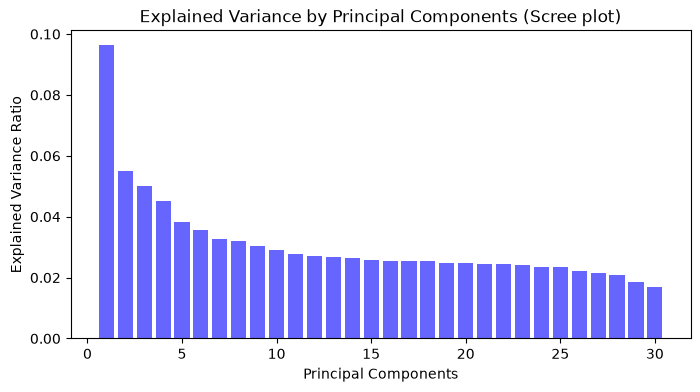

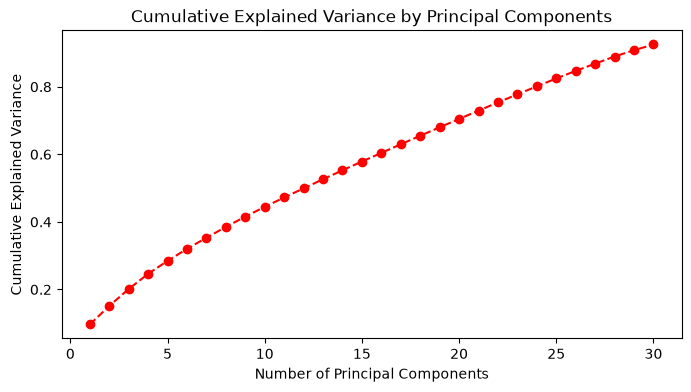

In [8]:
# X/y -split and scale the values
X = df.drop("income", axis=1)
y = df['income']

# scaling is needed in PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# define amount of PCA-variables => principal components
num_components = 30

# train the PCA -model
pca = PCA(n_components=num_components)
X_pca = pca.fit_transform(X_scaled)

# some basic metrics
explained_variance_ratio = pca.explained_variance_ratio_

print(f"Explained variance ratio with {num_components} components, by each component:\n{explained_variance_ratio}")
print(f"\nExplained variance ratio with {num_components} components, total result:\n{sum(explained_variance_ratio)}")

# 0.798 ~~ 80% of data preserved, which means we lost 20% of variance in the process
# aim to have less than 10% lost, or even less than 5% lost

X_reconstructed = pca.inverse_transform(X_pca)

# other metric is MSE => keep this as close to 0 as possible
# basically measures how much error the PCA model makes compared to original data
mse = mean_squared_error(X_scaled, X_reconstructed)
print(f"\nMean Squared Error (MSE) between original and reconstructed data:\n{mse}")
print(f"Average MSE per feature: {mse / X_scaled.shape[1]:.6f}")

# plot variance plots to see how much different components add to explainability
# plot 1: SCREE PLOT
plt.figure(figsize=(8, 4))
plt.bar(range(1, num_components + 1, ), explained_variance_ratio, alpha=0.6, color="b")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Components (Scree plot)")
plt.show()

# plot 2: cumulative explained variance
cumulative_variance = explained_variance_ratio.cumsum()
plt.figure(figsize=(8, 4))
plt.plot(range(1, num_components + 1, ), cumulative_variance, marker="o", linestyle='--', color="r")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance by Principal Components")
plt.show()

In [12]:
df_pca = pd.DataFrame(X_pca, columns=[f"PC{i + 1}" for i in range(num_components)])
df_pca.shape

(26887, 30)

* 10 components: 44.5% kept. 30 components:92.5% kept, MSE 0.075
* 41 > 30 columns
* The reduction is modest because the variance is spread almost evenly across the components.

In [ ]:
# With 30 components, the table would be unreadable, so let's just show the first 3 components
loadings = pca.components_
loadings_df = pd.DataFrame(
    loadings.T,
    columns=[f"PC{i + 1}" for i in range(loadings.shape[0])], index=X.columns
)

loadings_df[["PC1", "PC2", "PC3"]]

,PC1,PC2,PC3
age,0.222184,-0.236750,-0.182575
education.num,0.102526,-0.299062,0.163560
sex,-0.290375,-0.236868,-0.063695
capital.gain,0.080498,-0.064920,0.025223
capital.loss,0.070086,-0.026772,0.032873
hours.per.week,0.191778,-0.072491,0.019505
is_us,0.027936,-0.143565,0.236844
workclass_Federal-gov,0.019258,-0.140591,-0.060047
workclass_Local-gov,0.032175,-0.237451,-0.028388
workclass_Private,-0.168258,0.366559,0.001897


<Axes: >

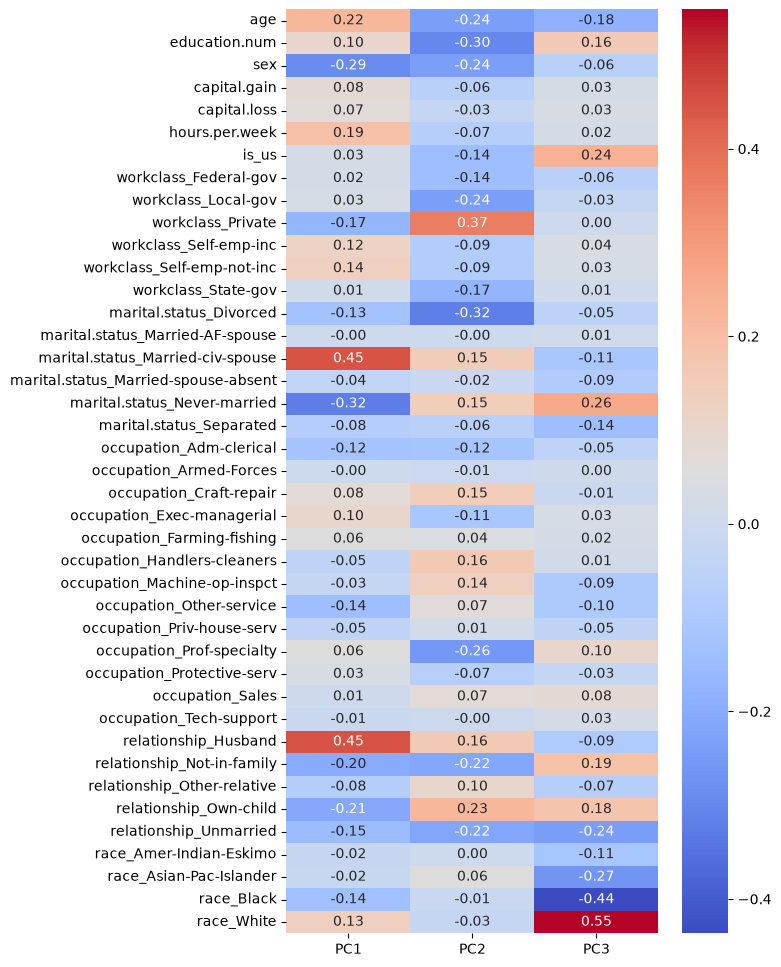

In [14]:
plt.figure(figsize=(6, 12))
sns.heatmap(loadings_df[["PC1", "PC2", "PC3"]], annot=True, fmt=".2f", cmap="coolwarm")

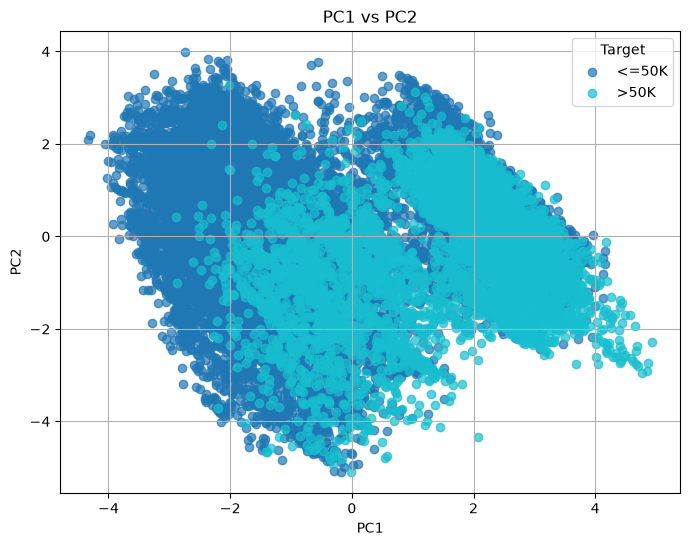

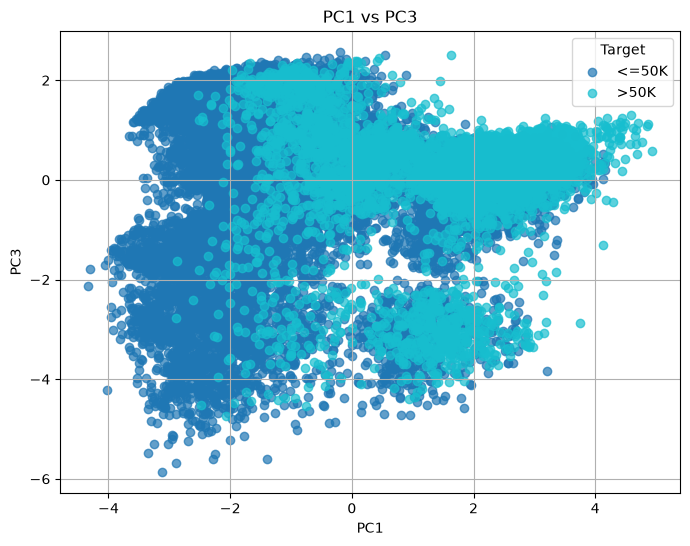

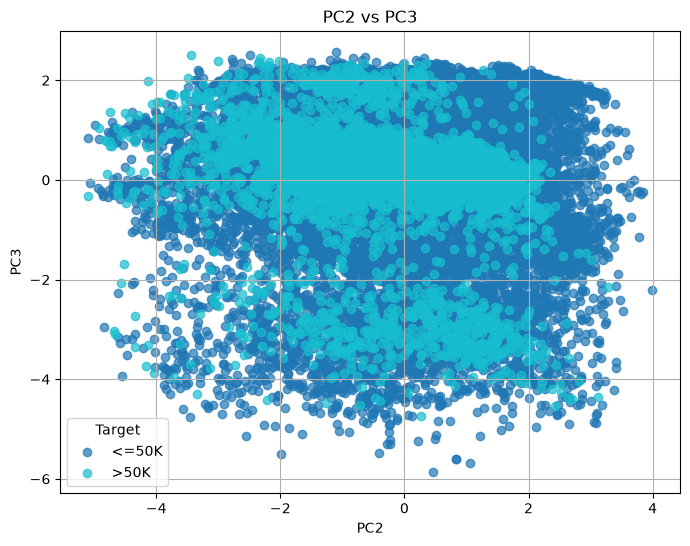

In [15]:
# helper functions to compare and visualize PC-variables

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

def plot_pca_pairs(pca_result, components, target=None):
    num_c = pca_result.shape[1]

    # Get unique target classes
    if target is not None:
        classes = np.unique(target)
        colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

    # Process each pair of PC variables
    for i in range(num_c):
        for j in range(i + 1, num_c):
            plt.figure(figsize=(8, 6))

            if target is not None:
                for cls, color in zip(classes, colors):
                    mask = target == cls

                    plt.scatter(
                        pca_result[mask, i],
                        pca_result[mask, j],
                        color=color,
                        alpha=0.7,
                        label=str(cls)
                    )

                plt.legend(title="Target")

            else:
                plt.scatter(
                    pca_result[:, i],
                    pca_result[:, j],
                    alpha=0.7
                )

            plt.title(f"PC{i+1} vs PC{j+1}")
            plt.xlabel(f"PC{i+1}")
            plt.ylabel(f"PC{j+1}")
            plt.grid(True)
            plt.show()

def plot_pca_pairs_with_clustering(pca_result, components, n_clusters=3):
    num_c = pca_result.shape[1]
    
    # Apply KMeans clustering
    kmeans = KMeans(n_clusters=n_clusters, random_state=1874)
    cluster_labels = kmeans.fit_predict(pca_result)
    
    # Process each pair of PC-variables and plot clusters
    for i in range(num_c):
        for j in range(i + 1, num_c):
            plt.figure(figsize=(8, 6))
            scatter = plt.scatter(pca_result[:, i], pca_result[:, j], c=cluster_labels, cmap='viridis', alpha=0.7)
            plt.title(f"PC{i+1} vs PC{j+1}")
            plt.xlabel(f"PC{i+1}")
            plt.ylabel(f"PC{j+1}")
            plt.grid(True)
            plt.colorbar(scatter, label='Cluster')
            plt.show()

    comparison = pd.crosstab(
        pd.Series(cluster_labels, name="Cluster"),
        pd.Series(y, name="Quality")
    )

    sns.heatmap(comparison, annot=True, fmt="d", cmap="Blues")

    plt.title("KMeans Clusters vs Actual Wine Quality")
    plt.show()

    print("Silhouette:",
      silhouette_score(pca_result, cluster_labels))

    print("Davies-Bouldin:",
        davies_bouldin_score(pca_result, cluster_labels))

    print("ARI:",
        adjusted_rand_score(y, cluster_labels))

    print("NMI:",
        normalized_mutual_info_score(y, cluster_labels))

plot_pca_pairs(X_pca[:, :3], 3, target=y.values)
# we can also use KMeans to visualize how well the data can be differentiated
# 3 is a good number to begin with for clusters, try also 6 (amount of options in the target)
# plot_pca_pairs_with_clustering(X_pca, pca.components_, n_clusters=8)

* The overlap is strong in the middle of PC1 and almost complete in the PC2 and PC3 plot.

* The clouds are widest along PC1, which fits PC1 explaining the most varaince. PC2 is a bit narrower, and PC3 forms stripes

* It seems that the column that drive the PC2 and PC3 (workclass_Private, divorced, education.num and race columns)(as we can see from the heatmap) don't separate income groups from the plots.